# Monitor a sensor stream for change

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OliverHennhoefer/nonconform/blob/main/examples/sensor_stream.ipynb)

A pump reports temperature, vibration and pressure once per step. Healthy
history is available. From step 300 a bearing starts to wear and vibration grows
slowly. The goal is an alarm soon after the change, and a known, small chance of
a false alarm on a healthy stream.

`ExchangeabilityMonitor` turns each new reading into a conformal p-value against
the healthy history and multiplies the evidence into a martingale. On a healthy
stream, the chance that the martingale ever crosses a threshold of 100 is at
most 1 in 100.

In [1]:
# On Colab or a fresh environment, install what this notebook needs.
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("nonconform") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "nonconform", "matplotlib"],
        check=True,
    )

In [2]:
import numpy as np
from sklearn.ensemble import IsolationForest

from nonconform import ConformalDetector, Split
from nonconform.martingales import AlarmConfig, SimpleJumperMartingale
from nonconform.monitoring import ExchangeabilityMonitor

rng = np.random.default_rng(42)


def pump_readings(n, wear):
    """Simulate temperature, vibration and pressure; wear inflates vibration."""
    temperature = rng.normal(60.0, 1.5, n)
    vibration = 2.0 + rng.normal(0.0, 1.0, n) * (1.0 + wear)
    pressure = 5.0 + rng.normal(0.0, 0.2, n) + 0.05 * (temperature - 60.0)
    return np.column_stack([temperature, vibration, pressure])


history = pump_readings(2_000, wear=0.0)
change_at = 300
steps = np.arange(600)
wear = np.clip((steps - change_at) / 100, 0.0, None)
stream = pump_readings(len(steps), wear=wear)

In [3]:
detector = ConformalDetector(
    detector=IsolationForest(random_state=42),
    strategy=Split(n_calib=0.5),
    score_polarity="auto",
    seed=42,
).fit(history)

threshold = 100.0
monitor = ExchangeabilityMonitor.from_split_detector(
    detector,
    martingale=SimpleJumperMartingale(
        alarm_config=AlarmConfig(restarted_ville_threshold=threshold)
    ),
    seed=42,
)

log10_evidence, alarm_at = [], None
for step, reading in enumerate(stream):
    state = monitor.update(reading)
    log10_evidence.append(state.martingale_state.log_restarted_martingale / np.log(10))
    if alarm_at is None and "restarted_ville" in state.triggered_alarms:
        alarm_at = step

print(f"Wear starts at step {change_at}, first alarm at step {alarm_at}")

Wear starts at step 300, first alarm at step 407


In [4]:
import matplotlib.pyplot as plt

NORMAL, ANOMALY, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#8a8984"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.8,
        "xtick.color": INK,
        "ytick.color": INK,
        "legend.frameon": False,
        "font.size": 10,
    }
)

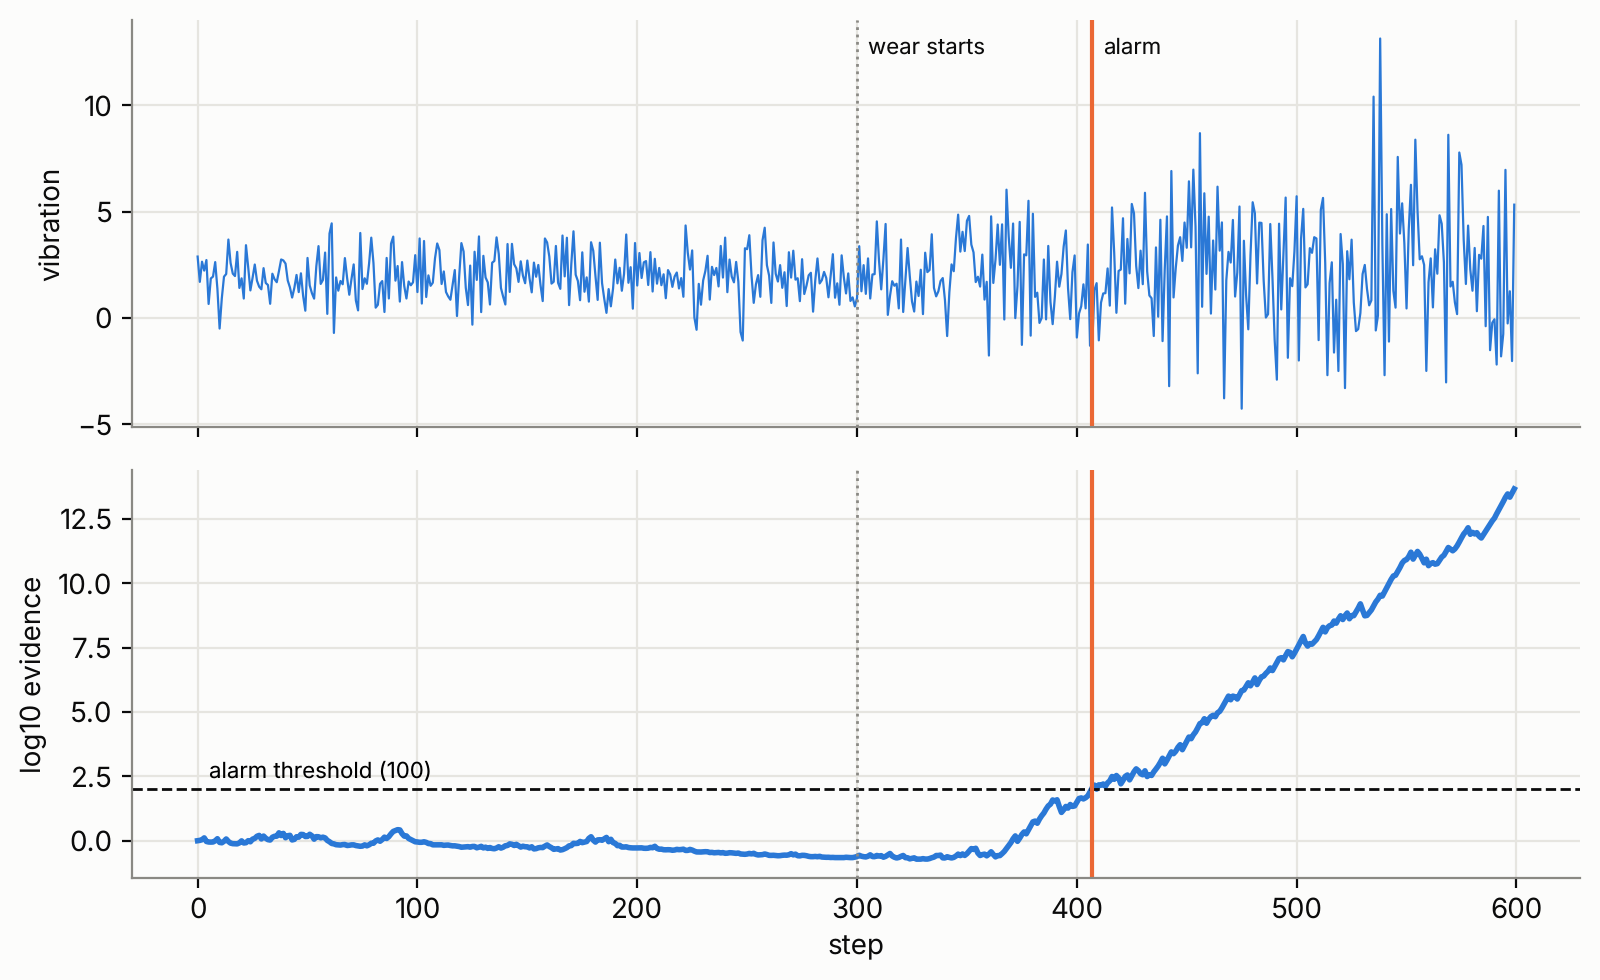

In [5]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
top.plot(steps, stream[:, 1], color=NORMAL, lw=0.8)
top.set_ylabel("vibration")
bottom.plot(steps, log10_evidence, color=NORMAL, lw=2)
bottom.axhline(np.log10(threshold), color=INK, lw=1, ls="--")
bottom.annotate(
    "alarm threshold (100)",
    (5, np.log10(threshold)),
    xytext=(0, 4),
    textcoords="offset points",
    fontsize=8,
)
bottom.set(xlabel="step", ylabel="log10 evidence")
for ax in (top, bottom):
    ax.axvline(change_at, color=MUTED, lw=1, ls=":")
    if alarm_at is not None:
        ax.axvline(alarm_at, color=ANOMALY, lw=1.5)
top.annotate(
    "wear starts",
    (change_at, top.get_ylim()[1]),
    xytext=(4, -12),
    textcoords="offset points",
    fontsize=8,
    color=INK,
)
if alarm_at is not None:
    top.annotate(
        "alarm",
        (alarm_at, top.get_ylim()[1]),
        xytext=(4, -12),
        textcoords="offset points",
        fontsize=8,
        color=INK,
    )
fig.tight_layout()
plt.show()

## What to take away

- The evidence stays near zero while the pump is healthy and climbs once the
  readings stop looking like the history.
- The threshold sets the false-alarm risk for one healthy stream: a threshold
  of `1 / alpha` keeps it at most `alpha`. It says nothing about which single
  reading is anomalous; for that, screen a batch with `select()`.
- The guarantee needs healthy history that is exchangeable with a healthy
  stream, and a detector fitted before monitoring starts. See *Assumptions and
  guarantees* in the docs.